# 02 — Trans2Vec

Notebook này chạy Trans2Vec trên 2 dataset:

- **Food:** tái thực nghiệm Bảng 2 của bài Trans2Vec (PAKDD 2018).
- **Foodmart utility:** áp dụng cùng quy trình lên dataset thứ hai.

Bốn phương pháp, đúng như Bảng 2 của bài:

| Tên | Mô tả |
|---|---|
| TRANS-IT | Doc2Vec (PV-DBOW) học từ các item của giao dịch |
| TRANS-FI | Doc2Vec học từ các frequent itemset (FI) của giao dịch |
| **Trans2Vec-IND** | Individual-training: trung bình vector của TRANS-IT và TRANS-FI, f(T) = (f₁(T) + f₂(T)) / 2 |
| **Trans2Vec-JOI** | Joint-training: Doc2Vec học từ item và FI cùng lúc |

Cấu hình lấy từ bài báo và code gốc (`trans2vec_ind_classify.py`, `trans2vec_joi_classify.py`):

| Tham số | Giá trị | Nguồn |
|---|---|---|
| Embedding | PV-DBOW (`dm=0`), d = 128, `min_count=0`, 50 epoch | bài báo mục 4.4 + code gốc |
| δ (minsup) | chọn bằng elbow method; Food: 0,2% | bài báo mục 4.4, Bảng 2 |
| Classifier | Linear SVM, C = 1, không tune | bài báo mục 4.3 |
| Đánh giá | Accuracy, F1-macro, trung bình 10 lần chạy | bài báo mục 4.3 |
| Train/test | Food 3.200/800; Foodmart 3.313/828 | notebook 01 |

Hai baseline BOW và TF-IDF của bài cũng được chạy để đối chiếu.

**Cách đọc bảng kết quả:** mỗi ô là `trung bình ± độ lệch chuẩn` qua 10 lần chạy (Doc2Vec có yếu tố ngẫu nhiên). BOW và TF-IDF không có yếu tố ngẫu nhiên nên chỉ chạy 1 lần. Dòng in đậm là phương pháp có accuracy cao nhất.

In [ ]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from utils import (DATA, PROCESSED, FIGURES, read_labeled, read_utility_db, mine_fi, elbow,
                   item_docs, pattern_docs, joint_docs, separate_pattern_tokens, run_embedding_methods,
                   baselines, log_results, nice, score_table)

food_split = json.load(open(PROCESSED / "food_split.json"))
fm_split = json.load(open(PROCESSED / "foodmart_split.json"))

## 1. Food — chọn δ bằng elbow method

Repo gốc có sẵn file FI đã mine ở 9 mức δ (từ 0,2% đến 1%). Ta đếm số FI ở mỗi mức và áp dụng elbow method: khi δ giảm, số FI tăng chậm rồi đột ngột tăng mạnh; ta chọn δ đầu tiên (đi từ cao xuống thấp) mà số FI tăng gấp đôi trở lên so với mức trước.

δ (%),Số FI,Được chọn
0.2,"9,975",←
0.3,"1,618",
0.4,"1,559",
0.5,"1,559",
0.6,"1,558",
0.7,"1,558",
0.8,"1,558",
0.9,"1,558",
1.0,"1,557",


Elbow method chọn δ = 0.2%


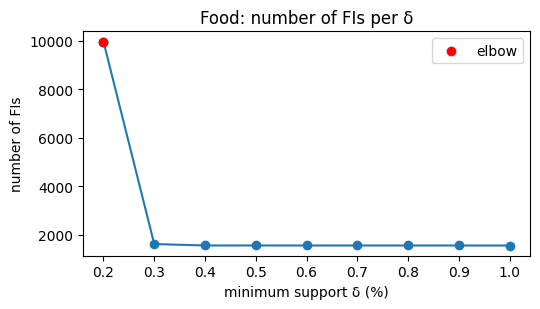

In [2]:
deltas = [0.002, 0.003, 0.004, 0.005, 0.006, 0.007, 0.008, 0.009, 0.01]
n_fis = []
for d in deltas:
    docs, _ = read_labeled(DATA / "food" / f"food_trans_fis_{d}.txt")
    n_fis.append(len({tok for doc in docs for tok in doc}))
food_delta = elbow(deltas, n_fis)

elbow_tab = pd.DataFrame({"δ (%)": [d * 100 for d in deltas], "Số FI": n_fis})
elbow_tab["Được chọn"] = np.where(np.isclose(elbow_tab["δ (%)"], food_delta * 100), "←", "")
display(nice(elbow_tab, digits=1, caption="Food: số FI theo δ"))
print(f"Elbow method chọn δ = {food_delta * 100:.1f}%")

fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.plot([d * 100 for d in deltas], n_fis, marker="o")
ax.scatter([food_delta * 100], [n_fis[deltas.index(food_delta)]], color="red", zorder=3, label="elbow")
ax.set_xlabel("minimum support δ (%)")
ax.set_ylabel("number of FIs")
ax.set_title("Food: number of FIs per δ")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "food_elbow_fi.png", dpi=150)
plt.show()

Elbow method chọn **δ = 0,2%**, đúng với giá trị bài báo dùng cho Food (dòng cuối Bảng 2).

Ở δ = 0,2% có 9.975 FI, gồm 1.559 FI một item và 8.416 FI nhiều item. Từ δ = 0,3% trở lên, số FI gần như bằng số item (1.559), tức gần như toàn FI một item.

## 2. Food — tái thực nghiệm

Ta dùng các file của repo gốc:

- `food.txt`: các item của giao dịch, dùng cho TRANS-IT.
- `food_trans_fis_0.002.txt`: các FI của giao dịch, dùng cho TRANS-FI và IND.
- JOI: ghép item và FI của hai file trên.

Trong file gốc, FI được đánh số từ 1, trùng tên với mã item (item `509` và FI `509` là cùng một chuỗi). Ta thêm tiền tố `p` cho token FI (`p1, p2, …`) để item và FI là hai loại token khác nhau, đúng như mô tả joint-training của bài.

In [ ]:
docs_it, y_food = read_labeled(DATA / "food" / "food.txt")
docs_fi, y_fi = read_labeled(DATA / "food" / f"food_trans_fis_{food_delta}.txt")
assert (y_food == y_fi).all()
docs_joi = joint_docs(docs_it, separate_pattern_tokens(docs_fi))

tr, te = np.array(food_split["train"]), np.array(food_split["test"])
food_base = baselines(docs_it, y_food, tr, te).query("method != 'LENGTH-ONLY'")
food_t2v = run_embedding_methods(docs_it, docs_fi, docs_joi, y_food, tr, te, pattern_name="FI", family="Trans2Vec")
food_res = pd.concat([food_base, food_t2v], ignore_index=True)
log_results(food_res, "Food", "Trans2Vec")
score_table(food_res, "Food — Trans2Vec")

### So sánh với Bảng 2 của bài báo

In [ ]:
paper_food = pd.DataFrame({
    "method": ["BOW", "TF-IDF", "TRANS-IT", "TRANS-FI", "Trans2Vec-IND", "Trans2Vec-JOI"],
    "Bài báo AC (%)": [63.12, 64.50, 65.95, 69.14, 69.22, 72.51],
    "Bài báo F1 (%)": [63.12, 64.49, 65.81, 68.95, 69.12, 72.47],
})
cmp_food = paper_food.merge(food_res[["method", "AC", "F1"]], on="method")
cmp_food = cmp_food.rename(columns={"method": "Phương pháp", "AC": "Nhóm AC (%)", "F1": "Nhóm F1 (%)"})
cmp_food["Chênh lệch AC"] = cmp_food["Nhóm AC (%)"] - cmp_food["Bài báo AC (%)"]
cmp_food.to_csv(PROCESSED / "food_reproduction_vs_paper.csv", index=False)
display(nice(cmp_food, caption="Food: tái thực nghiệm so với Bảng 2 của bài Trans2Vec"))

ac = food_res.set_index("method")["AC"]
worst = cmp_food.loc[cmp_food["Chênh lệch AC"].abs().idxmax()]
paper_order = ["TRANS-IT", "TRANS-FI", "Trans2Vec-IND", "Trans2Vec-JOI"]
print(f"Lệch lớn nhất so với bài: {worst['Chênh lệch AC']:+.2f} điểm ({worst['Phương pháp']})")
print("TRANS-FI cao hơn TRANS-IT (như bài):", "có" if ac["TRANS-FI"] > ac["TRANS-IT"] else "không")
print("JOI cao nhất trong 4 phương pháp embedding (như bài):",
      "có" if ac[paper_order].idxmax() == "Trans2Vec-JOI" else "không")

Mức lệch vài điểm phần trăm là chấp nhận được: ta dùng gensim 4.x thay vì 3.4, Doc2Vec có yếu tố ngẫu nhiên, và bài không công bố seed. Kết luận chung nằm ở cuối notebook 04.

## 3. Foodmart utility — áp dụng Trans2Vec

Foodmart không có file FI sẵn, nên ta tự mine bằng FP-Growth trên phần item của `foodmart.txt` (bỏ qua utility), rồi chọn δ cũng bằng elbow method. Foodmart rất thưa: item phổ biến nhất chỉ xuất hiện ở 0,6% số giao dịch, nên lưới δ được đặt theo số giao dịch tối thiểu (2, 3, 4, … giao dịch).

Token FI được thêm tiền tố `p` như ở Food (`pattern_docs` trong `utils.py`).

Số giao dịch tối thiểu,δ (%),Số FI,Được chọn
2,0.048,"4,247",←
3,0.072,"1,644",
4,0.097,"1,557",
5,0.121,"1,541",
6,0.145,"1,522",
8,0.193,"1,400",
10,0.241,"1,165",


Elbow method chọn δ = 0.048% (FI phải xuất hiện trong ít nhất 2 giao dịch)


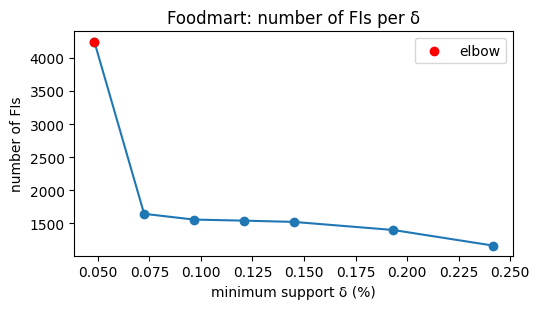

In [5]:
fm = read_utility_db(DATA / "utility" / "foodmart.txt")
fm_trans = [t[0] for t in fm]
fm_labels = pd.read_csv(PROCESSED / "foodmart_labels.csv")
y_fm = fm_labels["label"].to_numpy()
n_fm = len(fm_trans)

min_counts = [2, 3, 4, 5, 6, 8, 10]
fm_deltas = [c / n_fm for c in min_counts]
fm_fis = {d: mine_fi(fm_trans, d) for d in fm_deltas}
fm_counts = [len(fm_fis[d]) for d in fm_deltas]
fm_delta = elbow(fm_deltas, fm_counts)

elbow_tab = pd.DataFrame({"Số giao dịch tối thiểu": min_counts, "δ (%)": np.array(fm_deltas) * 100, "Số FI": fm_counts})
elbow_tab["Được chọn"] = np.where(np.isclose(fm_deltas, fm_delta), "←", "")
display(nice(elbow_tab, digits=3, caption="Foodmart: số FI theo δ"))
print(f"Elbow method chọn δ = {fm_delta * 100:.3f}% (FI phải xuất hiện trong ít nhất {round(fm_delta * n_fm)} giao dịch)")

fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.plot(np.array(fm_deltas) * 100, fm_counts, marker="o")
ax.scatter([fm_delta * 100], [len(fm_fis[fm_delta])], color="red", zorder=3, label="elbow")
ax.set_xlabel("minimum support δ (%)")
ax.set_ylabel("number of FIs")
ax.set_title("Foodmart: number of FIs per δ")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "foodmart_elbow_fi.png", dpi=150)
plt.show()

In [ ]:
fis = list(fm_fis[fm_delta].keys())
fm_docs_it = item_docs(fm_trans)
fm_docs_fi = pattern_docs(fm_trans, fis)
fm_docs_joi = joint_docs(fm_docs_it, fm_docs_fi)
print(f"Số FI dùng: {len(fis):,} (trong đó {sum(len(f) > 1 for f in fis):,} FI nhiều item)")
print(f"Giao dịch không chứa FI nào: {sum(len(d) == 0 for d in fm_docs_fi):,}")

tr, te = np.array(fm_split["train"]), np.array(fm_split["test"])
fm_base = baselines(fm_docs_it, y_fm, tr, te).query("method != 'LENGTH-ONLY'")
fm_t2v = run_embedding_methods(fm_docs_it, fm_docs_fi, fm_docs_joi, y_fm, tr, te, pattern_name="FI", family="Trans2Vec")
fm_res = pd.concat([fm_base, fm_t2v], ignore_index=True)
log_results(fm_res, "Foodmart", "Trans2Vec")
score_table(fm_res, "Foodmart — Trans2Vec")

Kết quả của hai dataset đã được ghi vào `results.csv`. Notebook 03 chạy Hui2Vec với cùng cấu hình, và notebook 04 tổng hợp so sánh.